Learning rate | Final loss | Epochs to reach loss < 0.10 | Std of loss (last 15 epochs)
        0.001 |     0.0933 | 38                          | 0.02317
         0.01 |     0.0501 | 5                           | 0.00054
          0.1 |     0.0482 | 2                           | 0.00023
          0.5 |     0.2099 | not reached                 | 0.01198


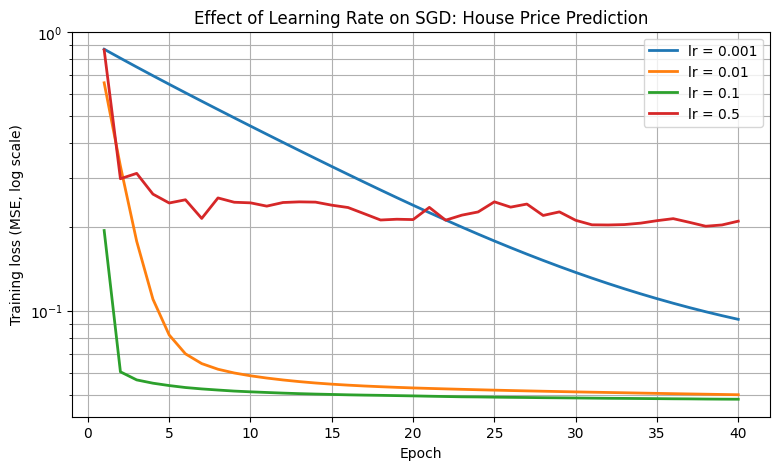

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

np.random.seed(2)

# Step 1: House data (area sq.ft, bedrooms, age years) -> price (lakhs)
n = 300
area = np.random.uniform(500, 3000, n)
bedrooms = np.random.randint(1, 5, n).astype(float)
age = np.random.uniform(0, 30, n)
price = 0.03 * area + 8 * bedrooms - 0.6 * age + np.random.normal(0, 5, n)
X = np.column_stack([area, bedrooms, age])
y = price.reshape(-1, 1)
X = (X - X.mean(axis=0)) / X.std(axis=0)
y = (y - y.mean()) / y.std()

# Step 2: Same network, trained with SGD at different learning rates
def build_model():
    tf.keras.utils.set_random_seed(2)
    return keras.Sequential([
        keras.layers.Input(shape=(3,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1)])

learning_rates = [0.001, 0.01, 0.1, 0.5]
epochs = 40
history = np.zeros((len(learning_rates), epochs))   # NumPy array of all losses

for i, lr in enumerate(learning_rates):
    model = build_model()
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss="mse")
    h = model.fit(X, y, epochs=epochs, batch_size=16, shuffle=True, verbose=0)
    history[i] = h.history["loss"]

# Step 3: Compare speed and stability
threshold = 0.10
print("Learning rate | Final loss | Epochs to reach loss < 0.10 | Std of loss (last 15 epochs)")
for i, lr in enumerate(learning_rates):
    reached = np.where(history[i] < threshold)[0]
    ep = int(reached[0]) + 1 if len(reached) else "not reached"
    print(f"{lr:13} | {history[i, -1]:10.4f} | {str(ep):27s} | {np.std(history[i, -15:]):.5f}")

# Step 4: Plot the loss curves
plt.figure(figsize=(9, 5))
for i, lr in enumerate(learning_rates):
    plt.plot(range(1, epochs + 1), history[i], linewidth=2, label=f"lr = {lr}")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training loss (MSE, log scale)")
plt.title("Effect of Learning Rate on SGD: House Price Prediction")
plt.legend()
plt.grid(True, which="both")
plt.show()